# Per-station overview

**Two pages per station** (NISAR, Sentinel-1), each with: NDVI/in-situ SM,
De Zan coherence/closure-phase vs. in-situ SM (per-track trend lines), and
the estimated-vs-in-situ SM timeseries (SME2+NISAR, or S1 alone). A page is
skipped if that satellite has no data for the station; a station is ignored
entirely if it has no in-situ data at all.

**"Good" tracks (Section 9's thresholds) are bold in the legend and get a
thick black dot outline** in every panel. Tracks with dead coherence (every
acquisition's saved GSLC window fully invalid) are dropped everywhere,
including the estimate-timeseries panel.

**Scatter-dot size is a significance signal**: coherence-panel size scales
with temporal baseline (shorter = bigger), closure-panel size with the
triplet's minimum pairwise coherence (higher = bigger) -- both fixed across
every station/page, so the same size always means the same value.

**Axes**: NDVI (0.2-1), coherence (0-1), and closure phase (0-pi) are fixed
across every station for comparability; everything else auto-scales to that
station's own data. The NDVI and estimate-timeseries panels share one
Volumetric Soil Moisture (%) y-range per station, across both its NISAR and
S1 pages. Track colors are consistent only within one station's own pages,
never reusing green (reserved for NDVI).

**In-situ gating**: an estimate, coherence pair, or closure triplet is only
plotted if every acquisition it depends on has a valid in-situ
interpolation at that date.

**Both depths**: per-station pages (Section 10) output 5cm and 20cm (up to
4 pages/station), each screened independently by its own Section 9
thresholds.

**Data sources** (all precomputed by other notebooks -- this notebook only
reads and plots, no new computation except station terrain):
- In-situ SM: `ismn_data/alaska/station_data/{station}_ts_0.05.csv` (5cm) /
  `_ts_0.20.csv` (20cm)
- NDVI: `nisar_data/alaska_HLS_ndvi/{station}_HLS_ndvi.csv`
- NISAR coherence/closure: `nisar_data/alaska_GSLC_coherence_closure/{station}_NISAR_GSLC_*.csv`
- Sentinel-1 coherence/closure: `S1_coherence_closure_alaska/{station}_orbit*_S1_*.csv`
- SME2: `SME2_data_alaska/sme2_cache.csv`
- NISAR/S1 SM estimates: `nisar_data/alaska_NISAR_SM_estimates.csv` / `S1_SM_estimates_alaska.csv`
  (written by `03a_estimate_sm_nisar.ipynb` / `03b_estimate_sm_s1.ipynb` --
  **re-run those first** for a fresh inversion run)
- Station terrain (slope): computed here from Copernicus GLO-30, same
  method as `util/nisar_station_timeseries.py`'s `compute_station_terrain`
  -- no Earthdata credentials needed.

In [ ]:
import sys
import os
from pathlib import Path

import pyproj
pyproj.datadir.set_data_dir(os.path.join(sys.prefix, "Library", "share", "proj"))


def require_globals(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f"Missing {missing} -- run the earlier setup cells first "
            "(the kernel may have been restarted)."
        )


BASE = Path.cwd()

COH_CLOSURE_DIR = BASE / "nisar_data" / "alaska_GSLC_coherence_closure"
NDVI_DIR = BASE / "nisar_data" / "alaska_HLS_ndvi"
INSITU_DIR = BASE / "ismn_data" / "alaska" / "station_data"
S1_COH_CLOSURE_DIR = BASE / "S1_coherence_closure_alaska"
SME2_CACHE_PATH = BASE / "SME2_data_alaska" / "sme2_cache.csv"
NISAR_SM_ESTIMATES_PATH = BASE / "nisar_data" / "alaska_NISAR_SM_estimates.csv"
S1_SM_ESTIMATES_PATH = BASE / "S1_SM_estimates_alaska.csv"

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

DATE_FORMATTER = mdates.DateFormatter("%b %d")

DEPTH_MAIN = 0.05
DEPTH_SECONDARY = 0.20

MAX_GAP_HOURS = 6
# Same safeguard the RMSE calculation notebooks use: a same-pass
# adjacent-frame pair/triplet leg can have a temporal baseline of seconds,
# which would otherwise show up as a near-zero-dSM point that's structurally
# guaranteed to look uninformative, not a real test of anything.
MIN_BASELINE_DAYS = 0.01

SENSOR_MARKER = {"NISAR": "o", "S1": "o"}
SIZE_MIN = 12
SIZE_MAX = 160
ALPHA_DOTS = 0.7
ALPHA_LEGEND = 0.75

FONT_SUPTITLE = 18
FONT_PANEL_TITLE = 13
FONT_AXIS_LABEL = 12
FONT_TICK = 11
FONT_LEGEND = 11

# Section 11's pooled scatter plots use their own, +2pt-larger font sizes
FONT_SUPTITLE_SCATTER = FONT_SUPTITLE + 2
FONT_PANEL_TITLE_SCATTER = FONT_PANEL_TITLE + 2
FONT_AXIS_LABEL_SCATTER = FONT_AXIS_LABEL + 2
FONT_TICK_SCATTER = FONT_TICK + 2
FONT_LEGEND_SCATTER = FONT_LEGEND + 2

# tab10 with green (index 2) dropped -- reserved for NDVI, see build_track_color_map
TRACK_COLOR_PALETTE = [c for i, c in enumerate(plt.cm.tab10(np.linspace(0, 1, 10))) if i != 2]

# Dot outline for a selected track (Section 9's thresholds), in both the
# estimate-timeseries panel and the coherence/closure-phase scatter panels
GOOD_TRACK_EDGE_COLOR = "black"
GOOD_TRACK_EDGE_WIDTH = 2.2
GOOD_TRACK_EDGE_WIDTH_ANCHOR = 2.6

# Per-station estimate-timeseries dot size, matched to the biggest possible dot in the
# coherence/closure scatter panels (SIZE_MAX) rather than its own small fixed size
ESTIMATE_DOT_SIZE = SIZE_MAX
ESTIMATE_ANCHOR_SIZE = SIZE_MAX + 60


C:\Users\geoka\miniconda3\envs\nisar-era5\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 1. Station list

In [2]:
require_globals("BASE")

stations_path = BASE / "ismn_data" / "alaska" / "stations.geojson"
with open(stations_path) as f:
    stations_geojson = json.load(f)

stations = {
    feat["properties"]["station_val"]: (
        feat["geometry"]["coordinates"][1],  # lat
        feat["geometry"]["coordinates"][0],  # lon
    )
    for feat in stations_geojson["features"]
}
print(f"Loaded {len(stations)} stations")


Loaded 20 stations


## 2. Data readers

Every reader returns `None` (or an empty DataFrame) when a station has no
file for that source -- every plot function below handles that by simply
leaving its panel empty, not by raising.

In [3]:
require_globals("INSITU_DIR", "NDVI_DIR", "COH_CLOSURE_DIR", "S1_COH_CLOSURE_DIR")


def read_insitu(station, depth=DEPTH_MAIN):
    path = INSITU_DIR / f"{station}_ts_{depth:.2f}.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    return df.iloc[:, 0].sort_index()  # single sm_<depth> column, whatever it's named


def interp_insitu_at(series, ts):
    before = series.loc[:ts]
    after = series.loc[ts:]
    if before.empty or after.empty:
        return np.nan
    t0, v0 = before.index[-1], before.iloc[-1]
    t1, v1 = after.index[0], after.iloc[0]
    if t0 == t1:
        return float(v0)
    gap_hours = (t1 - t0).total_seconds() / 3600.0
    if gap_hours > MAX_GAP_HOURS:
        return np.nan
    frac = (ts - t0).total_seconds() / (t1 - t0).total_seconds()
    return float(v0 + frac * (v1 - v0))


def _sm_diff_pct(df, series, col_a, col_b):
    a = df[col_a].apply(lambda ts: interp_insitu_at(series, ts))
    b = df[col_b].apply(lambda ts: interp_insitu_at(series, ts))
    return (a - b).abs() * 100


def _sm_range_pct(df, series, cols):
    vals = pd.concat([df[c].apply(lambda ts: interp_insitu_at(series, ts)) for c in cols], axis=1)
    return (vals.max(axis=1, skipna=False) - vals.min(axis=1, skipna=False)) * 100


def read_ndvi(station):
    path = NDVI_DIR / f"{station}_HLS_ndvi.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["target_date"])
    df = df[df["n_valid_px"] > 0]
    if df.empty:
        return None
    return df.set_index("target_date")["ndvi_mean"].sort_index()


def read_nisar_coherence(station):
    path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_coherence.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["date_1", "date_2"])
    return df[df["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()


def read_nisar_closure(station):
    path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_closure_phase.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["date_1", "date_2", "date_3"])
    keep = (
        (df["temporal_baseline_12_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_23_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_13_days"] >= MIN_BASELINE_DAYS)
    )
    return df[keep].copy()


def read_s1_coherence(station):
    dfs = [pd.read_csv(p, parse_dates=["date_1", "date_2"])
           for p in sorted(S1_COH_CLOSURE_DIR.glob(f"{station}_orbit*_S1_coherence.csv"))]
    if not dfs:
        return None
    df = pd.concat(dfs, ignore_index=True)
    return df[df["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()


def read_s1_closure(station):
    dfs = [pd.read_csv(p, parse_dates=["date_1", "date_2", "date_3"])
           for p in sorted(S1_COH_CLOSURE_DIR.glob(f"{station}_orbit*_S1_closure_phase.csv"))]
    if not dfs:
        return None
    df = pd.concat(dfs, ignore_index=True)
    keep = (
        (df["temporal_baseline_12_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_23_days"] >= MIN_BASELINE_DAYS)
        & (df["temporal_baseline_13_days"] >= MIN_BASELINE_DAYS)
    )
    return df[keep].copy()


## 3. SME2 and SM-estimate tables

In [4]:
sme2_df = (
    pd.read_csv(SME2_CACHE_PATH, parse_dates=["timestamp"])
    if SME2_CACHE_PATH.exists() else pd.DataFrame(columns=["station", "timestamp", "sm_pct"])
)
nisar_est_df = pd.read_csv(NISAR_SM_ESTIMATES_PATH, parse_dates=["date"])
s1_est_df = pd.read_csv(S1_SM_ESTIMATES_PATH, parse_dates=["date"])


def read_sme2(station):
    sub = sme2_df[sme2_df["station"] == station]
    if sub.empty:
        return None
    return sub.set_index("timestamp")["sm_pct"].sort_index()


def read_nisar_estimates(station, depth_label="5cm"):
    return nisar_est_df[(nisar_est_df["station"] == station) & (nisar_est_df["depth"] == depth_label)]


def read_s1_estimates(station, depth_label="5cm"):
    return s1_est_df[(s1_est_df["station"] == station) & (s1_est_df["depth"] == depth_label)]


print(f"SME2 cache: {sme2_df['station'].nunique()} station(s), {len(sme2_df)} row(s)")
print(f"NISAR SM estimates: {len(nisar_est_df)} row(s)")
print(f"S1 SM estimates: {len(s1_est_df)} row(s)")


SME2 cache: 7 station(s), 188 row(s)
NISAR SM estimates: 732 row(s)
S1 SM estimates: 224 row(s)


## 4. Station terrain (slope)

Reuses `util/nisar_station_timeseries.py`'s own
`compute_station_terrain` -- a 3x3 Copernicus GLO-30 window per station,
Horn's-method slope/aspect, streamed from the public DEM bucket (no
Earthdata login needed, unlike the GCOV/GSLC pipeline itself).

In [5]:
require_globals("BASE", "stations")

from util.nisar_station_timeseries import compute_station_terrain

station_dicts = [{"name": name, "lon": lon, "lat": lat} for name, (lat, lon) in stations.items()]
compute_station_terrain(station_dicts)
slope_by_station = {d["name"]: d["dem_slope_deg"] for d in station_dicts}
elevation_by_station = {d["name"]: d["dem_elevation_m"] for d in station_dicts}


Computing local terrain slope/aspect from Copernicus GLO-30 for each station...


Done. 18 unique DEM tiles used for 20 stations.
Slope range across stations: 0.51 - 9.41 deg (median 1.42 deg)


## 5. Stations to plot

Ignores any station with no in-situ data or with no SM estimatee (neither NISAR nor S1).

In [6]:
require_globals("stations", "read_nisar_estimates", "read_s1_estimates", "read_insitu")

_has_estimate = {s: (not read_nisar_estimates(s).empty or not read_s1_estimates(s).empty) for s in stations}
_has_insitu = {s: read_insitu(s) is not None for s in stations}

stations_to_plot = sorted(s for s in stations if _has_estimate[s] and _has_insitu[s])
no_estimate = sorted(s for s in stations if not _has_estimate[s])
no_insitu = sorted(s for s in stations if _has_estimate[s] and not _has_insitu[s])

print(f"{len(stations_to_plot)}/{len(stations)} station(s) have both a 5cm SM estimate and in-situ data -- plotting those")
if no_estimate:
    print(f"Skipped (no NISAR or S1 estimate): {no_estimate}")
if no_insitu:
    print(f"Skipped (no in-situ data at all): {no_insitu}")


15/20 station(s) have both a 5cm SM estimate and in-situ data -- plotting those
Skipped (no NISAR or S1 estimate): ['Aniak', 'MooseInc', 'Nenana', 'PrudhoeBay']
Skipped (no in-situ data at all): ['TurnagainPass']


## 6. Global temporal-baseline range

Coherence-panel dot size (Section 8) is scaled against a *fixed* baseline
range shared by every station/page, computed once here across all of
`stations_to_plot` -- so dot size means the same baseline length
everywhere, not a per-page rescaled one. The closure panel's min-coherence
sizing needs no such scan: coherence is already bounded to [0, 1].

In [7]:
require_globals("stations_to_plot")

_baseline_cols = []
for _station in stations_to_plot:
    for _df in (read_nisar_coherence(_station), read_s1_coherence(_station)):
        if _df is not None and not _df.empty:
            _baseline_cols.append(_df["temporal_baseline_days"].dropna())

GLOBAL_BASELINE_MIN = min(s.min() for s in _baseline_cols)
GLOBAL_BASELINE_MAX = max(s.max() for s in _baseline_cols)
print(f"Global temporal baseline range for dot sizing: "
      f"{GLOBAL_BASELINE_MIN:.2f}-{GLOBAL_BASELINE_MAX:.2f} days")


Global temporal baseline range for dot sizing: 12.00-79.00 days


## 7. Per-(station, satellite) track color map

One color per track/orbit, built fresh for each station+satellite page (not
once globally) from the *union* of tracks appearing in that satellite's
coherence data, closure data, and SM estimates -- so a track that (for
example) only ever appears in the estimates table still gets a stable color
and a legend entry, instead of silently falling back to gray and vanishing
from the legend.

In [ ]:
def _tracks_with_dead_coherence(station, sensor):
    """Tracks that have coherence-pair rows but all of them are NaN, for cases where every 
    acquisition's saved GSLC window had its mask flag every pixel invalid (0/255).
    Distinct from a track with no coherence rows at all (too few acquisitions to form a
    pair)."""
    if sensor == "NISAR":
        df, coh_col, track_col = read_nisar_coherence(station), "coherence_HH", "orbit_num"
    else:
        df, coh_col, track_col = read_s1_coherence(station), "coherence_VV", "orbit"
    if df is None or df.empty:
        return set()
    return {track for track, g in df.groupby(track_col) if g[coh_col].notna().sum() == 0}


def _sensor_all_tracks(station, sensor):
    if sensor == "NISAR":
        coh, clo, est = read_nisar_coherence(station), read_nisar_closure(station), read_nisar_estimates(station)
        coh_col = clo_col = "orbit_num"
        est_col = "track"
    else:
        coh, clo, est = read_s1_coherence(station), read_s1_closure(station), read_s1_estimates(station)
        coh_col = clo_col = est_col = "orbit"
    tracks = set()
    if coh is not None and not coh.empty:
        tracks |= set(coh[coh_col].unique())
    if clo is not None and not clo.empty:
        tracks |= set(clo[clo_col].unique())
    if est is not None and not est.empty:
        tracks |= set(est[est_col].unique())
    tracks -= _tracks_with_dead_coherence(station, sensor)
    return tracks


def _sensor_incidence_by_track(station, sensor):
    if sensor == "NISAR":
        coh, clo, track_col = read_nisar_coherence(station), read_nisar_closure(station), "orbit_num"
    else:
        coh, clo, track_col = read_s1_coherence(station), read_s1_closure(station), "orbit"
    result = {}
    if coh is not None and not coh.empty:
        result.update(coh.groupby(track_col)["local_incidence_angle_deg"].mean().to_dict())
    if clo is not None and not clo.empty and "local_incidence_angle_deg" in clo.columns:
        for track, v in clo.groupby(track_col)["local_incidence_angle_deg"].mean().items():
            result.setdefault(track, v)
    return result


def build_track_color_map(track_ids):
    """tab10 with green (index 2) dropped -- green is reserved for NDVI in the corresponding panel."""
    ids = sorted(track_ids)
    n = len(ids)
    if n == 0:
        return {}
    if n <= len(TRACK_COLOR_PALETTE):
        colors = TRACK_COLOR_PALETTE[:n]
    else:
        fracs = np.concatenate([np.linspace(0, 0.22, n - n // 2), np.linspace(0.48, 1.0, n // 2)])
        colors = plt.cm.turbo(fracs)
    return dict(zip(ids, colors))


## 8. Panel functions

One function per panel type. NDVI, coherence and closure phase  stay on a common scale across
every station for comparability.

In [ ]:
def _size_from_range(values, lo, hi, invert):
    """Map a data column to marker sizes in [SIZE_MIN, SIZE_MAX], against a
    *fixed* (lo, hi) range shared across every station/page -- not each
    page's own min/max -- so the same dot size means the same value on
    every page.

    invert=True: smallest value -> biggest dot (where the most significant 
    pair has the shortest baseline).
    invert=False: biggest value -> biggest dot (where the most "trustworthy"
    triplet is the most coherent).
    """
    values = np.asarray(values, dtype=float)
    if hi == lo:
        return np.full(values.shape, (SIZE_MIN + SIZE_MAX) / 2)
    frac = np.clip((values - lo) / (hi - lo), 0, 1)
    if invert:
        frac = 1 - frac
    return SIZE_MIN + frac * (SIZE_MAX - SIZE_MIN)


def _size_legend(ax, lo, hi, invert, fmt, title):
    if not np.isfinite(lo) or not np.isfinite(hi):
        return
    ref_vals = [lo, hi] if hi == lo else [lo, (lo + hi) / 2, hi]
    sizes = _size_from_range(np.array(ref_vals), lo, hi, invert)
    handles = [ax.scatter([], [], s=s, color="gray", alpha=ALPHA_LEGEND,
                           edgecolor="black", linewidth=0.4) for s in sizes]
    labels = [fmt(v) for v in ref_vals]
    ax.legend(handles, labels, title=title, fontsize=FONT_LEGEND, title_fontsize=FONT_LEGEND,
              loc="best", framealpha=ALPHA_LEGEND)


In [10]:
def plot_ndvi_insitu(ax, station, xlim, depth_label, depth_value):
    ax2 = ax.twinx()
    series = read_insitu(station, depth_value)
    if series is not None:
        ax.scatter(series.index, series.values * 100, color="black", s=4, alpha=0.4,
                   label="in-situ SM", zorder=2)
    ndvi = read_ndvi(station)
    if ndvi is not None:
        ax2.scatter(ndvi.index, ndvi.values, color="tab:green", s=18, alpha=ALPHA_DOTS,
                    label="NDVI", zorder=3)
    ax.set_ylabel("Volumetric Soil Moisture (%)", color="black", fontsize=FONT_AXIS_LABEL)
    ax2.set_ylabel("NDVI", color="tab:green", fontsize=FONT_AXIS_LABEL)
    ax2.set_ylim(0.2, 1)
    ax2.tick_params(axis="y", colors="tab:green", labelsize=FONT_TICK)
    ax.xaxis.set_major_formatter(DATE_FORMATTER)
    ax.tick_params(axis="x", rotation=45, labelsize=FONT_TICK)
    ax.tick_params(axis="y", labelsize=FONT_TICK)
    if xlim is not None:
        ax.set_xlim(*xlim)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    if h1 or h2:
        ax.legend(h1 + h2, l1 + l2, fontsize=FONT_LEGEND, loc="upper right", framealpha=ALPHA_LEGEND)
    ax.set_title(f"NDVI & in-situ SM ({depth_label})", fontsize=FONT_PANEL_TITLE)
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [11]:
def plot_coherence_single(ax, station, series, color_map, sensor, good_track_ids, depth_label):
    ax.set_xlabel("Absolute Soil Moisture Difference (%)", fontsize=FONT_AXIS_LABEL)
    ax.set_ylabel("Coherence", fontsize=FONT_AXIS_LABEL)
    ax.set_ylim(0, 1)
    ax.set_title(f"{sensor} coherence vs. Absolute Soil Moisture Difference ({depth_label})", fontsize=FONT_PANEL_TITLE)
    ax.tick_params(axis="both", labelsize=FONT_TICK)
    if sensor == "NISAR":
        df_all, coh_col, track_col = read_nisar_coherence(station), "coherence_HH", "orbit_num"
    else:
        df_all, coh_col, track_col = read_s1_coherence(station), "coherence_VV", "orbit"
    marker = SENSOR_MARKER[sensor]
    if df_all is None or series is None or df_all.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df = df_all.copy()
    df["dsm"] = _sm_diff_pct(df, series, "date_1", "date_2")
    valid = df[coh_col].notna() & df["dsm"].notna() & df["temporal_baseline_days"].notna()
    df = df.loc[valid]
    if df.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df["size"] = _size_from_range(df["temporal_baseline_days"].values,
                                   GLOBAL_BASELINE_MIN, GLOBAL_BASELINE_MAX, invert=True)
    for track, g in df.groupby(track_col):
        color = color_map.get(track, "gray")
        lw = GOOD_TRACK_EDGE_WIDTH if track in good_track_ids else 0.3
        ax.scatter(g["dsm"], g[coh_col], s=g["size"], color=color, marker=marker,
                   alpha=ALPHA_DOTS, edgecolor="black", linewidth=lw, zorder=3)
        if len(g) >= 2 and g["dsm"].std() > 0 and g[coh_col].std() > 0:
            x, y = g["dsm"].values, g[coh_col].values
            fit = np.polyfit(x, y, 1)
            xs = np.array([x.min(), x.max()])
            ax.plot(xs, np.polyval(fit, xs), "--", color=color, linewidth=1.2, zorder=2)
    _size_legend(ax, GLOBAL_BASELINE_MIN, GLOBAL_BASELINE_MAX, invert=True,
                 fmt=lambda v: f"{v:.1f} d", title="Temporal baseline")
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [12]:
def plot_closure_single(ax, station, series, color_map, sensor, good_track_ids, depth_label):
    ax.set_xlabel("SM range across triplet (%)", fontsize=FONT_AXIS_LABEL)
    ax.set_ylabel("|Closure phase| (rad)", fontsize=FONT_AXIS_LABEL)
    ax.set_ylim(0, np.pi)
    ax.set_title(f"{sensor} closure phase vs. SM range ({depth_label})", fontsize=FONT_PANEL_TITLE)
    ax.tick_params(axis="both", labelsize=FONT_TICK)
    if sensor == "NISAR":
        df_all, closure_col, track_col, mincoh_col = (
            read_nisar_closure(station), "closure_phase_HH", "orbit_num", "min_coherence_HH")
    else:
        df_all, closure_col, track_col, mincoh_col = (
            read_s1_closure(station), "closure_phase_VV", "orbit", "min_coherence_VV")
    marker = SENSOR_MARKER[sensor]
    if df_all is None or series is None or df_all.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df = df_all.copy()
    df["sm_range"] = _sm_range_pct(df, series, ["date_1", "date_2", "date_3"])
    df["abs_closure"] = df[closure_col].abs()
    valid = df["abs_closure"].notna() & df["sm_range"].notna() & df[mincoh_col].notna()
    df = df.loc[valid]
    if df.empty:
        ax.grid(True, alpha=0.3, linestyle="-", color="gray")
        return
    df["size"] = _size_from_range(df[mincoh_col].values, 0.0, 1.0, invert=False)
    for track, g in df.groupby(track_col):
        color = color_map.get(track, "gray")
        lw = GOOD_TRACK_EDGE_WIDTH if track in good_track_ids else 0.3
        ax.scatter(g["sm_range"], g["abs_closure"], s=g["size"], color=color, marker=marker,
                   alpha=ALPHA_DOTS, edgecolor="black", linewidth=lw, zorder=3)
        if len(g) >= 2 and g["sm_range"].std() > 0 and g["abs_closure"].std() > 0:
            x, y = g["sm_range"].values, g["abs_closure"].values
            fit = np.polyfit(x, y, 1)
            xs = np.array([x.min(), x.max()])
            ax.plot(xs, np.polyval(fit, xs), "--", color=color, linewidth=1.2, zorder=2)
    _size_legend(ax, 0.0, 1.0, invert=False,
                 fmt=lambda v: f"{v:.2f}", title="Min. coherence\n(triplet)")
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [13]:
def _filter_estimates_to_insitu(est_df, series):
    if series is None or est_df.empty:
        return est_df.iloc[0:0]
    valid_mask = est_df["date"].apply(lambda ts: not np.isnan(interp_insitu_at(series, ts)))
    return est_df.loc[valid_mask]


def _scatter_estimates(ax, est_df, id_col, sensor, color_map, good_track_ids):
    marker = SENSOR_MARKER[sensor]
    for track_id, g in est_df.groupby(id_col):
        color = color_map.get(track_id, "gray")
        is_good = track_id in good_track_ids
        edge_color = GOOD_TRACK_EDGE_COLOR  # black either way -- good tracks stand out by width alone
        lw_normal = GOOD_TRACK_EDGE_WIDTH if is_good else 0.3
        lw_anchor = GOOD_TRACK_EDGE_WIDTH_ANCHOR if is_good else 0.6
        normal = g[~g["is_dry_anchor"]]
        anchor = g[g["is_dry_anchor"]]
        ax.scatter(normal["date"], normal["sm_pct"], color=color, s=ESTIMATE_DOT_SIZE, marker=marker,
                   alpha=ALPHA_DOTS, edgecolor=edge_color, linewidth=lw_normal, zorder=3)
        ax.scatter(anchor["date"], anchor["sm_pct"], color=color, s=ESTIMATE_ANCHOR_SIZE, marker="*",
                   alpha=ALPHA_DOTS, edgecolor=edge_color, linewidth=lw_anchor, zorder=4)


def compute_station_xlim(station, depth_label, depth_value):
    series = read_insitu(station, depth_value)
    dates = []
    for reader, sensor, id_col in (
        (read_nisar_estimates, "NISAR", "track"), (read_s1_estimates, "S1", "orbit"),
    ):
        est = _filter_estimates_to_insitu(reader(station, depth_label), series)
        if not est.empty:
            dead = _tracks_with_dead_coherence(station, sensor)
            est = est[~est[id_col].isin(dead)]
        if not est.empty:
            dates.append(est["date"].min())
            dates.append(est["date"].max())
    if not dates:
        return None
    pad = pd.Timedelta(hours=24)
    return (min(dates) - pad, max(dates) + pad)


def plot_estimate_timeseries_single(ax, station, sensor, color_map, xlim, good_track_ids, depth_label, depth_value):
    ax.set_ylabel("Volumetric Soil Moisture (%)", fontsize=FONT_AXIS_LABEL)
    ax.xaxis.set_major_formatter(DATE_FORMATTER)
    ax.tick_params(axis="x", rotation=45, labelsize=FONT_TICK)
    ax.tick_params(axis="y", labelsize=FONT_TICK)
    series = read_insitu(station, depth_value)
    sme2 = read_sme2(station) if sensor == "NISAR" and depth_label == "5cm" else None
    ax.set_title(f"{sensor} estimates vs in-situ SM ({depth_label})", fontsize=FONT_PANEL_TITLE)
    if series is not None:
        ax.scatter(series.index, series.values * 100, color="black", s=3, alpha=0.3,
                   label="in-situ", zorder=1)
    if sme2 is not None:
        ax.scatter(sme2.index, sme2.values, color="dimgray", marker="^", s=35, alpha=ALPHA_DOTS,
                   label="SME2", zorder=2)
    est_raw = read_nisar_estimates(station, depth_label) if sensor == "NISAR" else read_s1_estimates(station, depth_label)
    est = _filter_estimates_to_insitu(est_raw, series)
    if not est.empty:
        id_col = "track" if sensor == "NISAR" else "orbit"
        est = est[~est[id_col].isin(_tracks_with_dead_coherence(station, sensor))]
    if not est.empty:
        _scatter_estimates(ax, est, id_col, sensor, color_map, good_track_ids)
    if xlim is not None:
        ax.set_xlim(*xlim)
    handles, labels = ax.get_legend_handles_labels()
    if not est.empty and est["is_dry_anchor"].any():
        handles.append(Line2D([0], [0], marker="*", color="none", markerfacecolor="gray",
                               markeredgecolor="black", markeredgewidth=0.6, markersize=10))
        labels.append("dry anchor")
    if handles:
        ax.legend(handles, labels, fontsize=FONT_LEGEND, loc="upper right", framealpha=ALPHA_LEGEND)
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")


In [14]:
def sync_sm_ylim(axes):
    """Every given axes plots Volumetric Soil Moisture (%) on its primary
    y-axis (the NDVI panel and the estimate-timeseries panel, across *both*
    a station's NISAR and S1 pages) -- give them all the same range so the
    same height means the same SM value everywhere for that station, not
    just within one page."""
    axes = [ax for ax in axes if ax is not None]
    if not axes:
        return
    lo = min(ax.get_ylim()[0] for ax in axes)
    hi = max(ax.get_ylim()[1] for ax in axes)
    for ax in axes:
        ax.set_ylim(lo, hi)


In [15]:
def build_track_legend_handles(sensor, color_map, incidence_by_track, good_track_ids):
    """Handles/labels for a track-color/incidence-angle legend -- returned
    rather than drawn into its own axes, so the caller can place it as one
    shared `fig.legend` instead of a dedicated grid cell of floating
    whitespace. Also returns a parallel is_good list so the caller can bold
    the legend text for tracks in `good_track_ids` (Section 9's
    selection) after the Legend object exists."""
    marker = SENSOR_MARKER[sensor]
    tracks = sorted(color_map.keys())
    handles, labels, is_good = [], [], []
    for track in tracks:
        color = color_map[track]
        inc = incidence_by_track.get(track)
        inc_str = f"{inc:.0f}\u00b0" if inc is not None and not np.isnan(inc) else "n/a"
        handles.append(Line2D([0], [0], marker=marker, color="none", markerfacecolor=color,
                               markeredgecolor="black", markeredgewidth=0.4, markersize=9,
                               alpha=ALPHA_LEGEND))
        labels.append(f"Track {track} ({inc_str})")
        is_good.append(track in good_track_ids)
    return handles, labels, is_good


## 9. Track quality screening

Per-(station, satellite, track) -- e.g. NISAR track 44 at EagleSummit and
at Coldfoot are two different entries, never pooled by track number alone.
Three metrics per track: **average coherence** and **average
\|closure phase\|** (physical InSAR quality, over every baseline-filtered
pair/triplet, not restricted to in-situ-covered ones), and **RMSE** against
5cm in-situ SM (same exclusions `03a`/`03b` use: dry-anchor point and
non-interpolatable dates excluded).

**Bar-plot checks** -- mean coherence, mean \|closure phase\|, and NDVI
std, one row per depth, one panel per sensor, RMSE < 6% tracks green vs. >
6% red -- show how well each metric alone separates accurate from
inaccurate tracks. Should  help the user decide the threshold values.

**Selection thresholds** are decided by visually checking those bar-plots. They are then hardcoded
as plain numbers in `SELECTION_THRESHOLDS` in the next cell. A track is *selected* if its
coherence is above, its \|closure phase\| below, and its station's NDVI
std below its depth+sensor's thresholds. The selected set is what Section 10 highlights and
Sections 11/12 call "selected."

In [16]:
require_globals("stations_to_plot")

SENSOR_COH_COL = {"NISAR": "coherence_HH", "S1": "coherence_VV"}
SENSOR_CLOSURE_COL = {"NISAR": "closure_phase_HH", "S1": "closure_phase_VV"}
SENSOR_TRACK_COL = {"NISAR": "orbit_num", "S1": "orbit"}
SENSOR_COH_READER = {"NISAR": read_nisar_coherence, "S1": read_s1_coherence}
SENSOR_CLOSURE_READER = {"NISAR": read_nisar_closure, "S1": read_s1_closure}
SENSOR_EST_READER = {"NISAR": read_nisar_estimates, "S1": read_s1_estimates}
SENSOR_EST_ID_COL = {"NISAR": "track", "S1": "orbit"}
RMSE_THRESHOLD_PCT = 6.0  # 0.06 volumetric fraction


def _track_avg_coherence(station, sensor, track):
    df = SENSOR_COH_READER[sensor](station)
    if df is None or df.empty:
        return np.nan, 0
    col, track_col = SENSOR_COH_COL[sensor], SENSOR_TRACK_COL[sensor]
    vals = df.loc[df[track_col] == track, col].dropna()
    return (float(vals.mean()), len(vals)) if len(vals) else (np.nan, 0)


def _track_avg_abs_closure(station, sensor, track):
    df = SENSOR_CLOSURE_READER[sensor](station)
    if df is None or df.empty:
        return np.nan, 0
    col, track_col = SENSOR_CLOSURE_COL[sensor], SENSOR_TRACK_COL[sensor]
    vals = df.loc[df[track_col] == track, col].dropna().abs()
    return (float(vals.mean()), len(vals)) if len(vals) else (np.nan, 0)


def _track_rmse_points(station, sensor, track, depth_label, depth_value):
    """(real_pct, est_pct) arrays of valid (non-dry-anchor, in-situ-covered)
    points at depth_label/depth_value for this track -- same exclusions
    03a_estimate_sm_nisar.ipynb / 03b_estimate_sm_s1.ipynb use for their own RMSE."""
    series = read_insitu(station, depth_value)
    if series is None:
        return np.array([]), np.array([])
    est = SENSOR_EST_READER[sensor](station, depth_label)
    id_col = SENSOR_EST_ID_COL[sensor]
    est = est[(est[id_col] == track) & (~est["is_dry_anchor"])]
    if est.empty:
        return np.array([]), np.array([])
    real_pct = np.array([interp_insitu_at(series, ts) for ts in est["date"]]) * 100
    est_pct = est["sm_pct"].values
    valid = ~np.isnan(real_pct) & ~np.isnan(est_pct)
    return real_pct[valid], est_pct[valid]


def compute_track_metrics(depth_label, depth_value):
    """One row per (station, satellite, track). avg_coherence/avg_abs_closure
    are depth-independent; rmse_pct is computed against depth_label/depth_value."""
    rows = []
    for station in stations_to_plot:
        for sensor in ["NISAR", "S1"]:
            for track in sorted(_sensor_all_tracks(station, sensor)):
                avg_coh, n_coh = _track_avg_coherence(station, sensor, track)
                avg_clo, n_clo = _track_avg_abs_closure(station, sensor, track)
                real_pct, est_pct = _track_rmse_points(station, sensor, track, depth_label, depth_value)
                rmse = float(np.sqrt(np.mean((est_pct - real_pct) ** 2))) if len(real_pct) else np.nan
                rows.append({
                    "station": station, "sensor": sensor, "track": track,
                    "avg_coherence": avg_coh, "n_coh_pairs": n_coh,
                    "avg_abs_closure": avg_clo, "n_closure_triplets": n_clo,
                    "rmse_pct": rmse, "n_rmse_points": len(real_pct),
                    "_real_pct": real_pct, "_est_pct": est_pct,
                })
    return pd.DataFrame(rows)


track_metrics_df = compute_track_metrics("5cm", DEPTH_MAIN)
track_metrics_df_20cm = compute_track_metrics("20cm", DEPTH_SECONDARY)
print(f"5cm: {len(track_metrics_df)} (station, satellite, track) entries across "
      f"{track_metrics_df['station'].nunique()} station(s)")
print(f"20cm: {len(track_metrics_df_20cm)} (station, satellite, track) entries across "
      f"{track_metrics_df_20cm['station'].nunique()} station(s)")


5cm: 87 (station, satellite, track) entries across 15 station(s)
20cm: 87 (station, satellite, track) entries across 15 station(s)


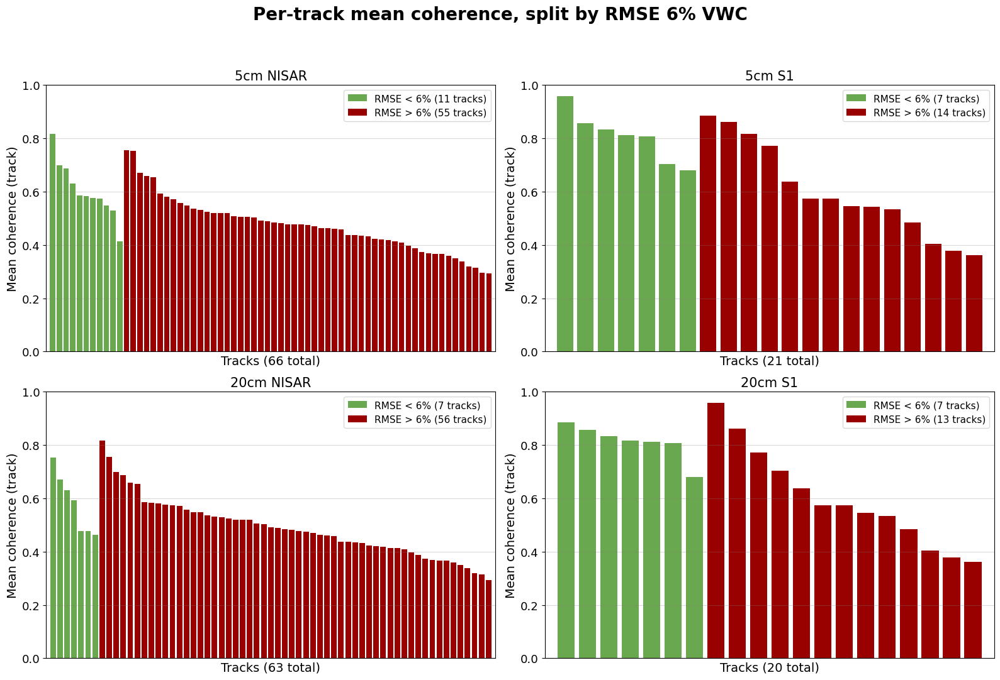

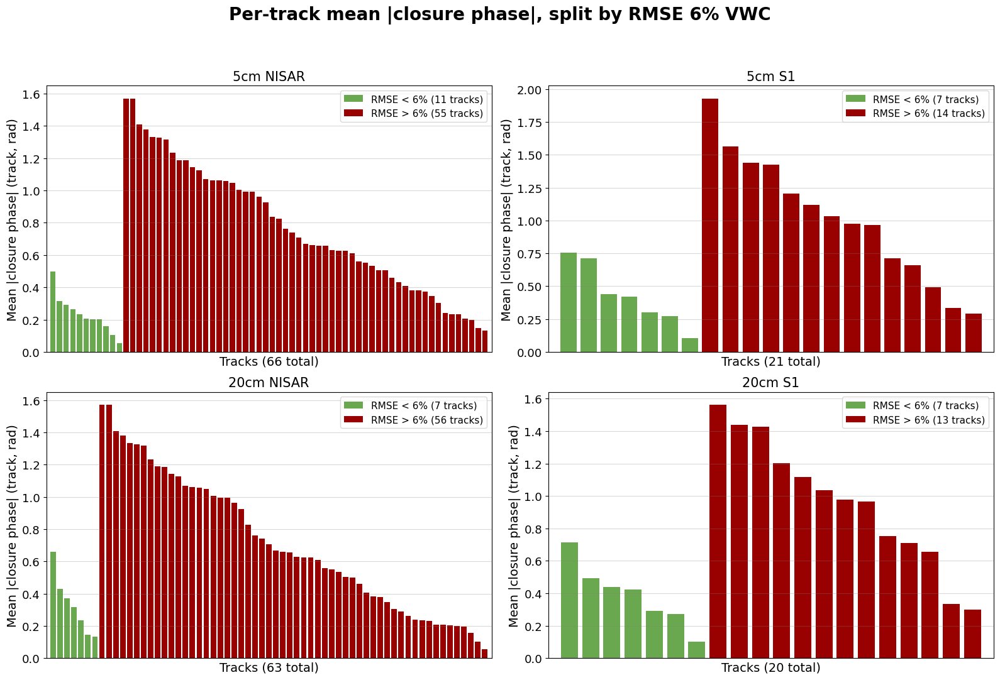

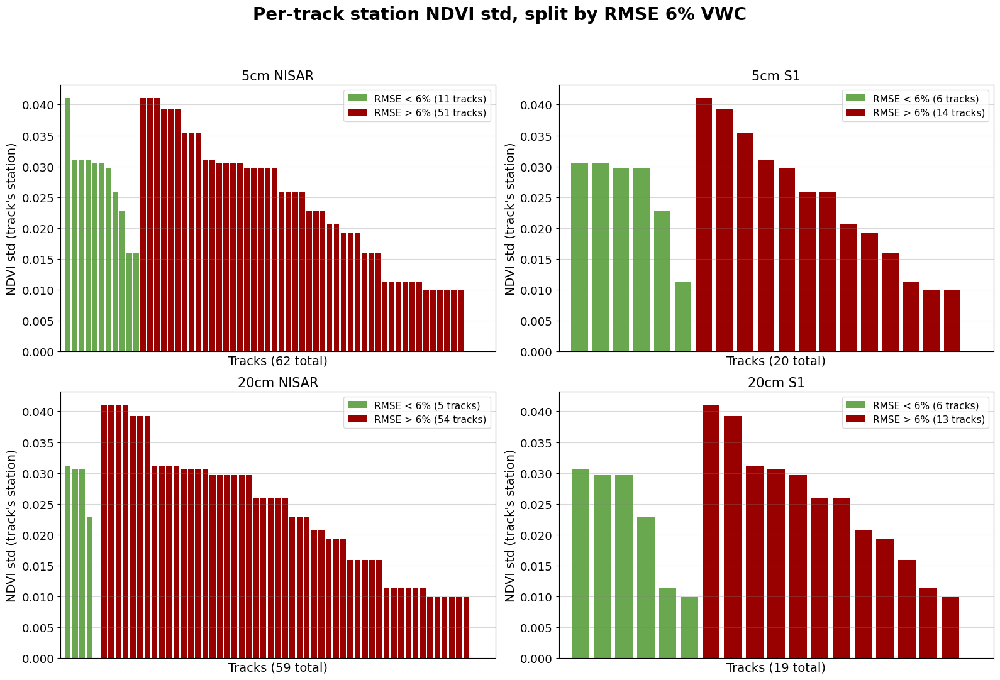

In [ ]:
require_globals("track_metrics_df", "track_metrics_df_20cm", "RMSE_THRESHOLD_PCT")

BAR_COLOR_LOW_RMSE = "#6aa84f"
BAR_COLOR_HIGH_RMSE = "#990000"


def plot_track_metric_bars(metrics_by_depth, value_col, ylabel, title_metric, ylim=None,
                           rmse_threshold_pct=RMSE_THRESHOLD_PCT):
    """One row per depth, one panel per sensor: one bar per track (its `value_col`),
    RMSE-below-threshold tracks in green on the left, RMSE-above in red on the right,
    each group sorted descending by the value. Tracks with no in-situ value (thus no RMSE),
    can't be plotted and are left out."""
    depths = list(metrics_by_depth)
    fig, axes = plt.subplots(len(depths), 2, figsize=(16, 5.5 * len(depths)), squeeze=False)
    for row, depth_label in enumerate(depths):
        df = metrics_by_depth[depth_label]
        for col, sensor in enumerate(["NISAR", "S1"]):
            ax = axes[row, col]
            d = df[(df["sensor"] == sensor) & df["rmse_pct"].notna() & df[value_col].notna()]
            low = d[d["rmse_pct"] < rmse_threshold_pct].sort_values(value_col, ascending=False)
            high = d[d["rmse_pct"] >= rmse_threshold_pct].sort_values(value_col, ascending=False)
            ax.bar(np.arange(len(low)), low[value_col], color=BAR_COLOR_LOW_RMSE, width=0.8,
                   label=f"RMSE < {rmse_threshold_pct:.0f}% ({len(low)} tracks)")
            ax.bar(np.arange(len(high)) + len(low), high[value_col], color=BAR_COLOR_HIGH_RMSE, width=0.8,
                   label=f"RMSE > {rmse_threshold_pct:.0f}% ({len(high)} tracks)")
            ax.set_xlim(-1, len(d))
            if ylim:
                ax.set_ylim(*ylim)
            ax.set_xticks([])
            ax.set_title(f"{depth_label} {sensor}", fontsize=FONT_PANEL_TITLE_SCATTER)
            ax.set_xlabel(f"Tracks ({len(d)} total)", fontsize=FONT_AXIS_LABEL_SCATTER)
            ax.set_ylabel(ylabel, fontsize=FONT_AXIS_LABEL_SCATTER)
            ax.tick_params(axis="y", labelsize=FONT_TICK_SCATTER)
            ax.grid(True, axis="y", alpha=0.3, linestyle="-", color="gray")
            ax.legend(fontsize=FONT_LEGEND_SCATTER - 2, loc="upper right", framealpha=ALPHA_LEGEND)
    fig.suptitle(f"Per-track {title_metric}, split by RMSE {rmse_threshold_pct:.0f}% VWC",
                 fontsize=FONT_SUPTITLE_SCATTER, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


def _with_station_ndvi_std(df):
    stds = {st: (read_ndvi(st).values.std() if read_ndvi(st) is not None else np.nan)
            for st in df["station"].unique()}
    return df.assign(ndvi_std=df["station"].map(stds))


metrics_by_depth = {"5cm": track_metrics_df, "20cm": track_metrics_df_20cm}

plot_track_metric_bars(metrics_by_depth, "avg_coherence", "Mean coherence (track)",
                       "mean coherence", ylim=(0, 1))
plot_track_metric_bars(metrics_by_depth, "avg_abs_closure", "Mean |closure phase| (track, rad)",
                       "mean |closure phase|")
plot_track_metric_bars({d: _with_station_ndvi_std(m) for d, m in metrics_by_depth.items()}, "ndvi_std",
                       "NDVI std (track's station)", "station NDVI std")


The thresholds that signify a "good" track can't be universal (for all AOIs and date ranges).
These values should be decided by the user instead, after visually checking the bar-plots above.
The threshold values below, are mere placeholders (that emerged from the Alaska experiment).
**Change them with your values of choice**.

In [ ]:
require_globals("track_metrics_df", "track_metrics_df_20cm", "read_ndvi")

SELECTION_THRESHOLDS = {
    "5cm": {
        "NISAR": {"coherence": 0.53, "closure": 0.31, "ndvi_std": 0.031},
        "S1":    {"coherence": 0.67, "closure": 0.75, "ndvi_std": 0.031},
    },
    "20cm": {
        "NISAR": {"coherence": 0.58, "closure": 0.33, "ndvi_std": 0.021},
        "S1":    {"coherence": 0.81, "closure": 0.39, "ndvi_std": 0.021},
    },
}


def _station_ndvi_std_below(station, thr):
    nd = read_ndvi(station)
    return nd is not None and nd.values.std() < thr["ndvi_std"]


def select_tracks(df, thresholds):
    """Tracks with avg_coherence above, avg_abs_closure below, and the track's own
    station NDVI std below their sensor's threshold (thresholds: one depth's
    per-sensor dict)."""
    keep = [
        idx for idx, row in df.iterrows()
        if row["avg_coherence"] > thresholds[row["sensor"]]["coherence"]
        and row["avg_abs_closure"] < thresholds[row["sensor"]]["closure"]
        and _station_ndvi_std_below(row["station"], thresholds[row["sensor"]])
    ]
    return df.loc[keep]


def run_selection(df, thresholds, depth_label):
    print(f"=== {depth_label} selection thresholds ===")
    for sensor, thr in thresholds.items():
        print(f"  {sensor}: coherence > {thr['coherence']:.3f}, |closure phase| < {thr['closure']:.3f} rad, "
              f"station NDVI std < {thr['ndvi_std']:.3f}")

    good_df = select_tracks(df, thresholds)
    print(f"\n{len(good_df)}/{len(df)} track(s) selected:")
    print(good_df.drop(columns=["_real_pct", "_est_pct"]).to_string(index=False))

    pooled_real = np.concatenate(good_df["_real_pct"].values) if len(good_df) else np.array([])
    pooled_est = np.concatenate(good_df["_est_pct"].values) if len(good_df) else np.array([])
    if len(pooled_real):
        print(f"\nPooled RMSE across all {len(pooled_real)} point(s) from these {len(good_df)} track(s): "
              f"{np.sqrt(np.mean((pooled_est - pooled_real) ** 2)):.2f}% VWC")
    else:
        print("\nNo RMSE points available among the selected tracks.")

    good_tracks = set(zip(good_df["station"], good_df["sensor"], good_df["track"]))
    print(f"\n{len(good_tracks)} track(s) will be highlighted (bold legend entry, thick black dot outline) "
          f"in Section 10's {depth_label} per-station pages.\n")
    return good_df, good_tracks


good_df, good_tracks = run_selection(track_metrics_df, SELECTION_THRESHOLDS["5cm"], "5cm")
good_df_20cm, good_tracks_20cm = run_selection(track_metrics_df_20cm, SELECTION_THRESHOLDS["20cm"], "20cm")


=== 5cm selection thresholds ===
  NISAR: coherence > 0.530, |closure phase| < 0.310 rad, station NDVI std < 0.031
  S1: coherence > 0.670, |closure phase| < 0.750 rad, station NDVI std < 0.031

18/87 track(s) selected:
          station sensor  track  avg_coherence  n_coh_pairs  avg_abs_closure  n_closure_triplets  rmse_pct  n_rmse_points
      EagleSummit  NISAR     15       0.557233            6         0.207949                   4  9.311592              3
      EagleSummit  NISAR    164       0.699986           10         0.158895                  10  1.492345              4
      EagleSummit     S1     94       0.857240           15         0.422104                  20  5.125638              4
      EagleSummit     S1    123       0.817781           15         0.293859                  20  6.942272              4
      EagleSummit     S1    160       0.959469            6         0.299023                   4  3.054943              3
     GobblersKnob  NISAR     63       0.671793  

## 10. Per-station, per-satellite pages

Output at **both depths** -- a station with both, gets 4 pages (NISAR/S1 x
5cm/20cm), each screened independently by its own Section 9 thresholds. The 
selected tracks are mentioned in bold and a thick black dot outline in every 
panel.

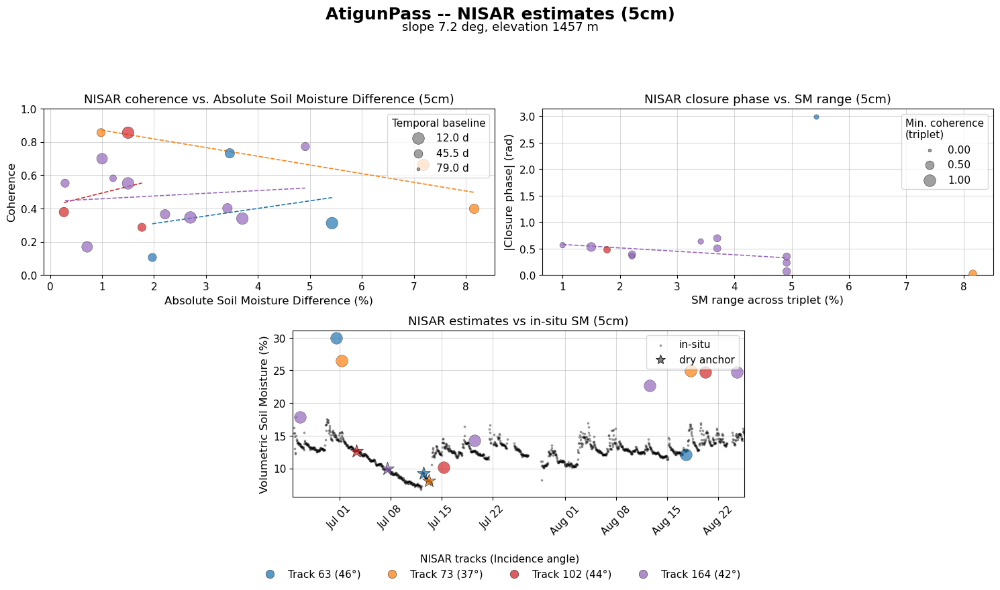

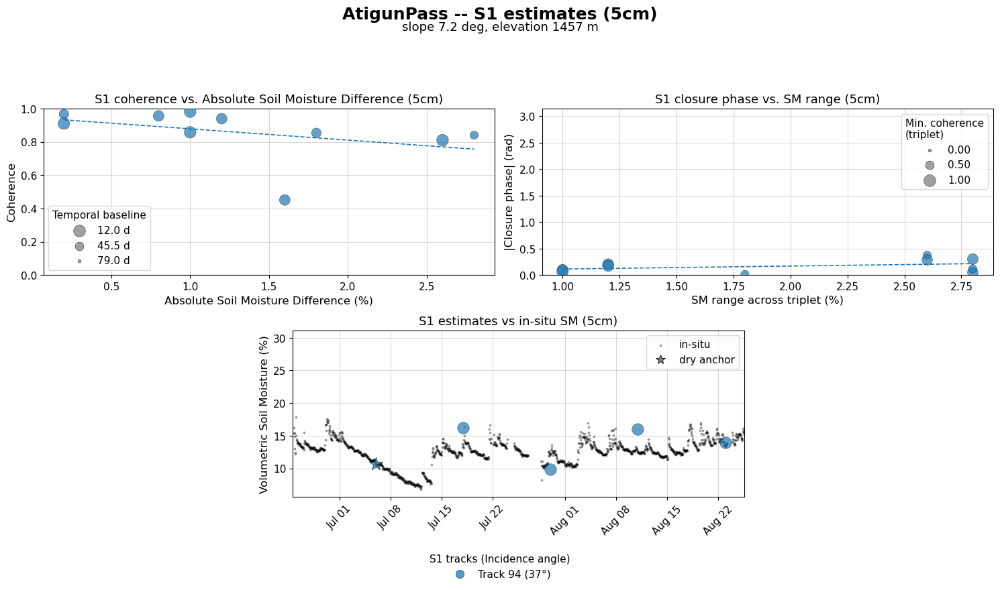

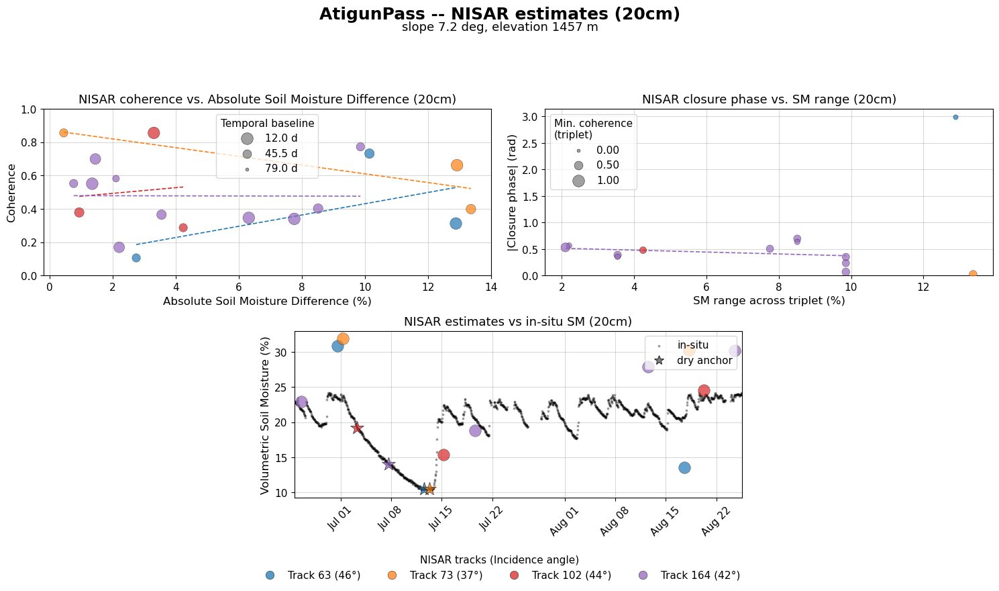

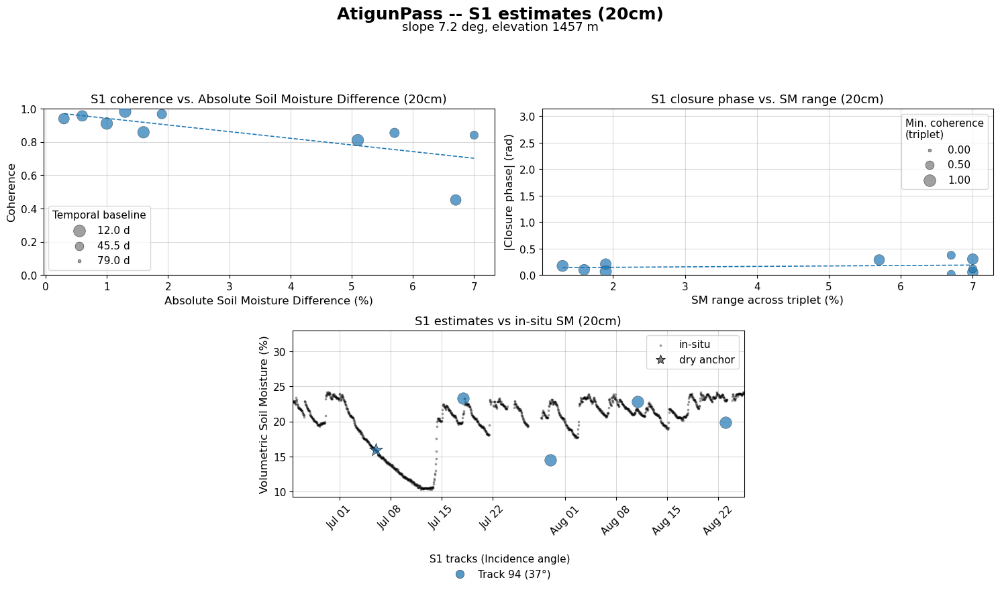

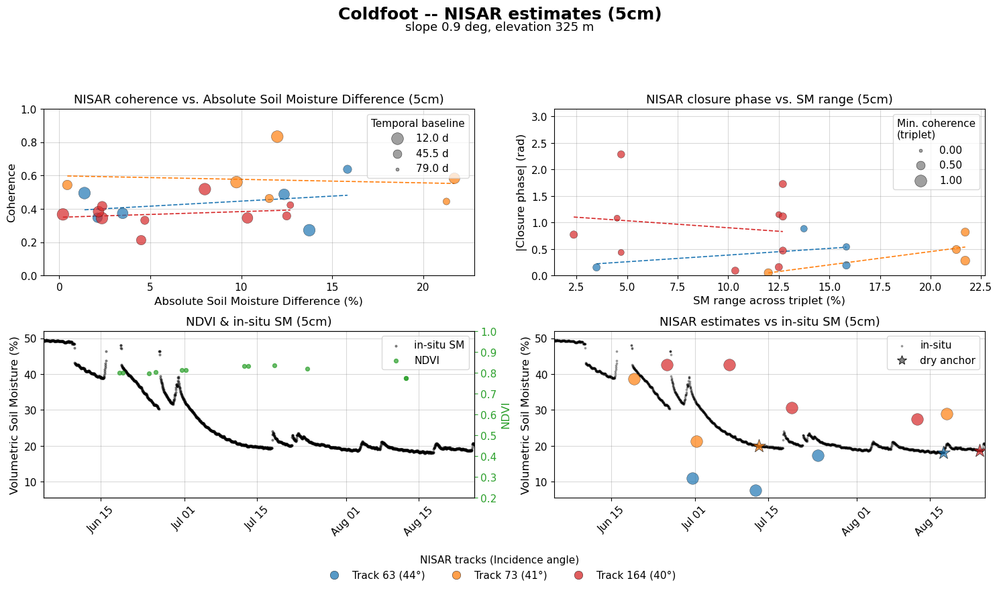

...

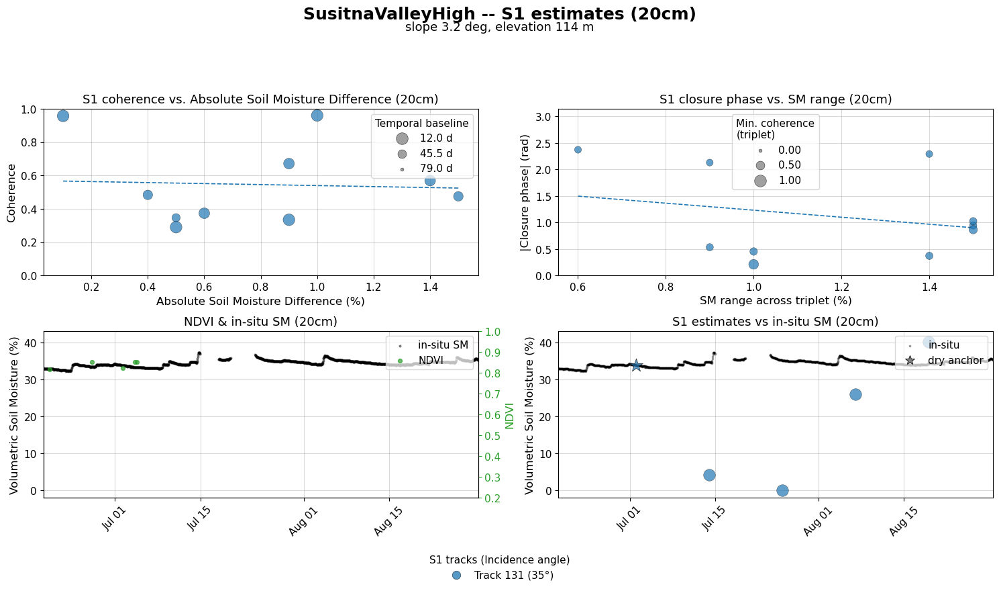

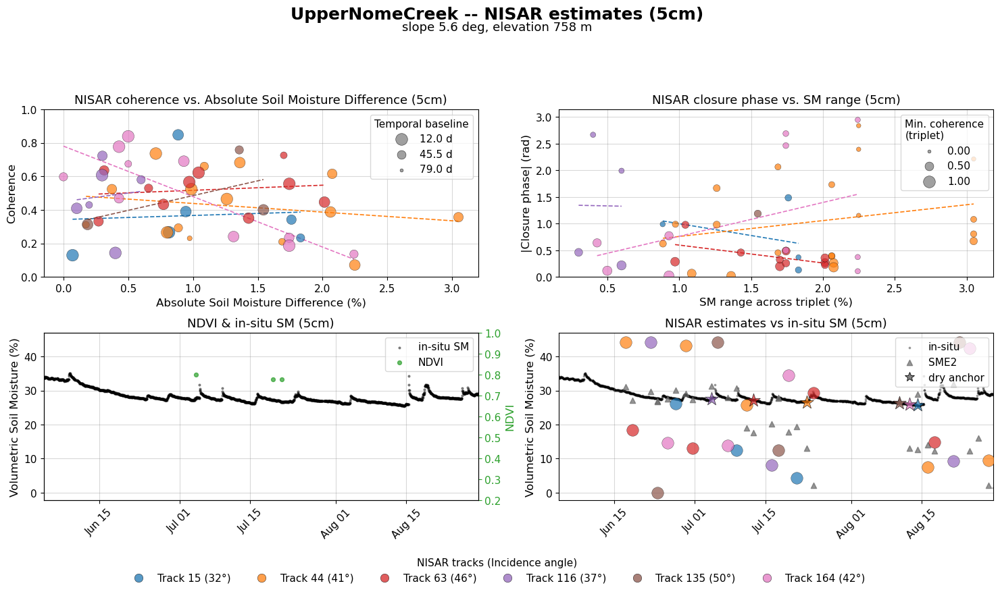

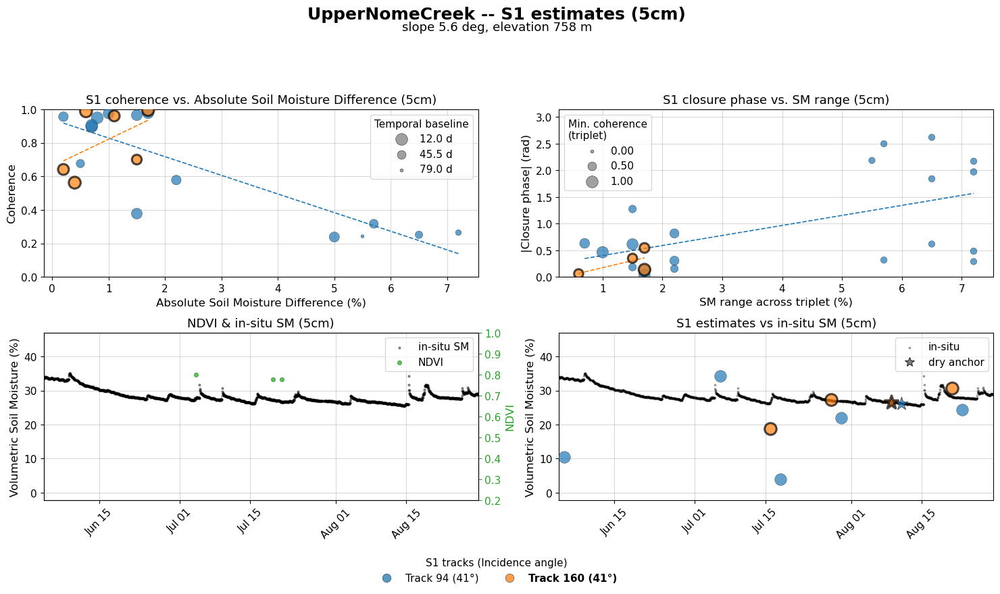

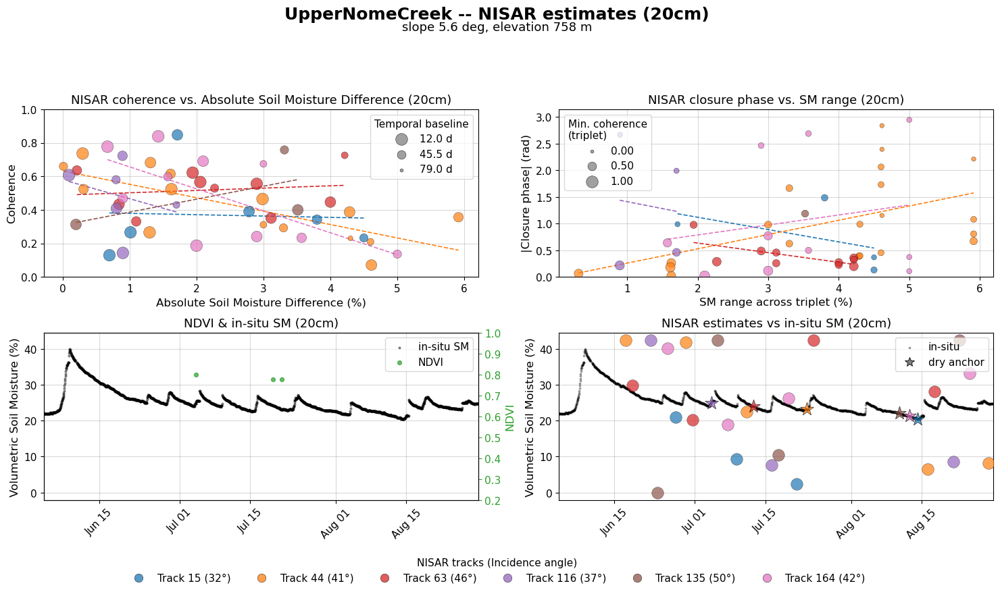

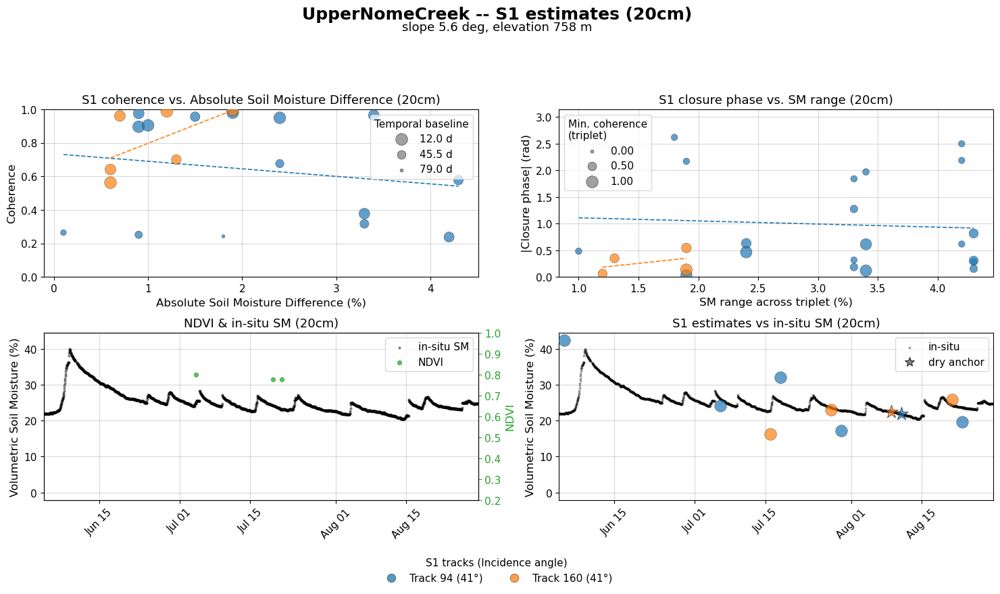

In [19]:
require_globals("stations_to_plot", "slope_by_station", "elevation_by_station",
                 "good_tracks", "good_tracks_20cm")

import matplotlib.gridspec as gridspec

DEPTHS = [("5cm", DEPTH_MAIN, good_tracks), ("20cm", DEPTH_SECONDARY, good_tracks_20cm)]

for station in stations_to_plot:
    slope = slope_by_station.get(station, np.nan)
    elev = elevation_by_station.get(station, np.nan)
    slope_str = f"{slope:.1f} deg" if not np.isnan(slope) else "n/a"
    elev_str = f"{elev:.0f} m" if not np.isnan(elev) else "n/a"

    for depth_label, depth_value, depth_good_tracks in DEPTHS:
        series = read_insitu(station, depth_value)
        if series is None:
            continue
        has_ndvi = read_ndvi(station) is not None
        xlim = compute_station_xlim(station, depth_label, depth_value)

        pages = []  # (fig, ax_ndvi_or_None, ax_ts) -- built for both sensors before either is
                    # shown, so their shared Volumetric Soil Moisture (%) axes can be synced
                    # across the station's NISAR and S1 pages, not just within one page
        for sensor in ["NISAR", "S1"]:
            tracks = _sensor_all_tracks(station, sensor)
            if not tracks:
                continue
            color_map = build_track_color_map(tracks)
            incidence_by_track = _sensor_incidence_by_track(station, sensor)
            page_good_tracks = {t for (s, se, t) in depth_good_tracks if s == station and se == sensor}

            fig = plt.figure(figsize=(15, 9))
            # 2x4: each normal panel is 2 sub-columns wide (0:2 or 2:4), so a lone
            # timeseries panel with no NDVI to share the row can be centered at 1:3 --
            # same width as every other panel, just shifted to the row's middle,
            # rather than stretched to fill the whole row.
            gs = gridspec.GridSpec(2, 4, figure=fig)
            ax_coh, ax_clo = fig.add_subplot(gs[0, 0:2]), fig.add_subplot(gs[0, 2:4])
            if has_ndvi:
                ax_ndvi, ax_ts = fig.add_subplot(gs[1, 0:2]), fig.add_subplot(gs[1, 2:4])
            else:
                ax_ndvi, ax_ts = None, fig.add_subplot(gs[1, 1:3])

            plot_coherence_single(ax_coh, station, series, color_map, sensor, page_good_tracks, depth_label)
            plot_closure_single(ax_clo, station, series, color_map, sensor, page_good_tracks, depth_label)
            if has_ndvi:
                plot_ndvi_insitu(ax_ndvi, station, xlim, depth_label, depth_value)
            plot_estimate_timeseries_single(ax_ts, station, sensor, color_map, xlim, page_good_tracks,
                                             depth_label, depth_value)

            fig.suptitle(f"{station} -- {sensor} estimates ({depth_label})", fontsize=FONT_SUPTITLE,
                         fontweight="bold", y=0.975)
            fig.text(0.5, 0.935, f"slope {slope_str}, elevation {elev_str}",
                     ha="center", fontsize=FONT_PANEL_TITLE, fontweight="normal")
            fig.tight_layout(rect=[0, 0.08, 1, 0.89])

            handles, labels, is_good_list = build_track_legend_handles(
                sensor, color_map, incidence_by_track, page_good_tracks)
            if handles:
                leg = fig.legend(handles, labels, loc="lower center", ncol=min(len(labels), 6),
                                  fontsize=FONT_LEGEND, title=f"{sensor} tracks (Incidence angle)",
                                  title_fontsize=FONT_LEGEND, frameon=False, bbox_to_anchor=(0.5, 0.01))
                for text, is_good in zip(leg.get_texts(), is_good_list):
                    if is_good:
                        text.set_fontweight("bold")

            pages.append((fig, ax_ndvi if has_ndvi else None, ax_ts))

        sm_axes = [ax for _, ax_ndvi, ax_ts in pages for ax in (ax_ndvi, ax_ts)]
        sync_sm_ylim(sm_axes)

        for fig, _ax_ndvi, _ax_ts in pages:
            plt.show()


## 11. Selected-track scatter plots (5cm)

Three pooled 1:1 scatter plots at 5cm, using only points from tracks
selected by Section 9. Each panel's annotation has n, the number of
contributing tracks/stations, RMSE, bias, and r.

1. Selected NISAR estimates vs. in-situ SM
2. Selected S1 estimates vs. in-situ SM
3. SME2 vs. in-situ SM -- not track-restricted, annotated by station count

Section 12 repeats these at 20cm, with its own independently selected
track set.

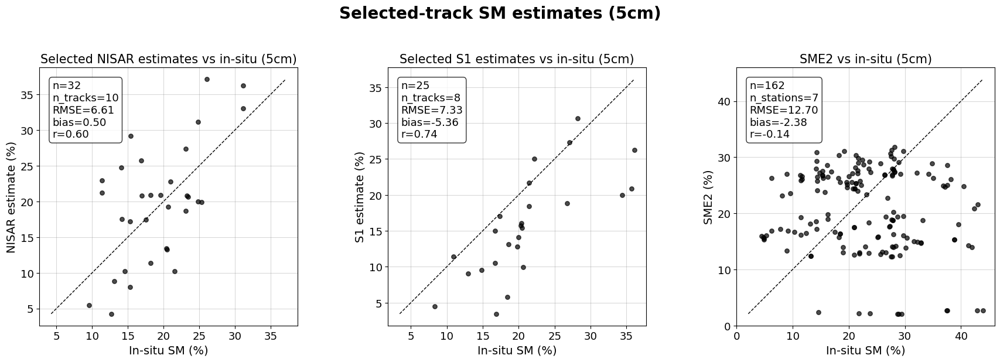

In [20]:
require_globals("stations_to_plot", "good_tracks")


def _pooled_estimates_vs_insitu(sensor, good_tracks_set, depth_label, depth_value):
    """(real_pct, est_pct, n_tracks_used) -- n_tracks_used counts only
    selected tracks that actually contributed >=1 valid point, not every
    track in good_tracks_set for this sensor."""
    id_col = SENSOR_EST_ID_COL[sensor]
    reader = SENSOR_EST_READER[sensor]
    real_out, est_out = [], []
    tracks_used = set()
    for station in stations_to_plot:
        series = read_insitu(station, depth_value)
        if series is None:
            continue
        est = reader(station, depth_label)
        est = est[~est["is_dry_anchor"]]
        if est.empty:
            continue
        for track, g in est.groupby(id_col):
            if (station, sensor, track) not in good_tracks_set:
                continue
            real = np.array([interp_insitu_at(series, ts) for ts in g["date"]]) * 100
            estp = g["sm_pct"].values
            valid = ~np.isnan(real) & ~np.isnan(estp)
            if valid.any():
                tracks_used.add((station, track))
            real_out.append(real[valid])
            est_out.append(estp[valid])
    real_arr = np.concatenate(real_out) if real_out else np.array([])
    est_arr = np.concatenate(est_out) if est_out else np.array([])
    return real_arr, est_arr, len(tracks_used)


def _pooled_sme2_vs_insitu(depth_value):
    """(real_pct, sme2_pct, n_stations_used) -- SME2 isn't per-track, so the
    contributor count is stations, not tracks."""
    real_out, sme2_out = [], []
    stations_used = set()
    for station in stations_to_plot:
        sme2 = read_sme2(station)
        if sme2 is None:
            continue
        series = read_insitu(station, depth_value)
        if series is None:
            continue
        real = np.array([interp_insitu_at(series, ts) for ts in sme2.index]) * 100
        valid = ~np.isnan(real)
        if not valid.any():
            continue
        stations_used.add(station)
        real_out.append(real[valid])
        sme2_out.append(sme2.values[valid])
    real_arr = np.concatenate(real_out) if real_out else np.array([])
    sme2_arr = np.concatenate(sme2_out) if sme2_out else np.array([])
    return real_arr, sme2_arr, len(stations_used)


def _scatter_1to1(ax, x, y, xlabel, ylabel, title, n_label):
    ax.set_xlabel(xlabel, fontsize=FONT_AXIS_LABEL_SCATTER)
    ax.set_ylabel(ylabel, fontsize=FONT_AXIS_LABEL_SCATTER)
    ax.set_title(title, fontsize=FONT_PANEL_TITLE_SCATTER)
    ax.tick_params(axis="both", labelsize=FONT_TICK_SCATTER)
    ax.grid(True, alpha=0.3, linestyle="-", color="gray")
    if len(x) == 0:
        ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes,
                fontsize=FONT_AXIS_LABEL_SCATTER)
        return
    ax.scatter(x, y, color="black", s=28, alpha=ALPHA_DOTS, zorder=3)
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([lo, hi], [lo, hi], "k--", linewidth=1, zorder=2)
    rmse = np.sqrt(np.mean((y - x) ** 2))
    bias = np.mean(y - x)
    r = np.corrcoef(x, y)[0, 1] if len(x) > 1 and np.std(x) > 0 and np.std(y) > 0 else np.nan
    ax.text(0.05, 0.95, f"n={len(x)}\n{n_label}\nRMSE={rmse:.2f}\nbias={bias:.2f}\nr={r:.2f}",
            transform=ax.transAxes, va="top", fontsize=FONT_LEGEND_SCATTER,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    ax.set_aspect("equal", adjustable="box")


def plot_good_track_scatter_figure(depth_label, depth_value, good_tracks_set, suptitle):
    real_n, est_n, n_tracks_n = _pooled_estimates_vs_insitu("NISAR", good_tracks_set, depth_label, depth_value)
    real_s1, est_s1, n_tracks_s1 = _pooled_estimates_vs_insitu("S1", good_tracks_set, depth_label, depth_value)
    real_sme2i, sme2_i, n_stations_sme2 = _pooled_sme2_vs_insitu(depth_value)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    _scatter_1to1(axes[0], real_n, est_n, "In-situ SM (%)", "NISAR estimate (%)",
                  f"Selected NISAR estimates vs in-situ ({depth_label})", f"n_tracks={n_tracks_n}")
    _scatter_1to1(axes[1], real_s1, est_s1, "In-situ SM (%)", "S1 estimate (%)",
                  f"Selected S1 estimates vs in-situ ({depth_label})", f"n_tracks={n_tracks_s1}")
    _scatter_1to1(axes[2], real_sme2i, sme2_i, "In-situ SM (%)", "SME2 (%)",
                  f"SME2 vs in-situ ({depth_label})", f"n_stations={n_stations_sme2}")

    fig.suptitle(suptitle, fontsize=FONT_SUPTITLE_SCATTER, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.90])
    plt.show()


plot_good_track_scatter_figure("5cm", DEPTH_MAIN, good_tracks, "Selected-track SM estimates (5cm)")


## 12. Selected-track scatter plots (20cm)

Section 11's same 3 pooled scatter plots, at 20cm.

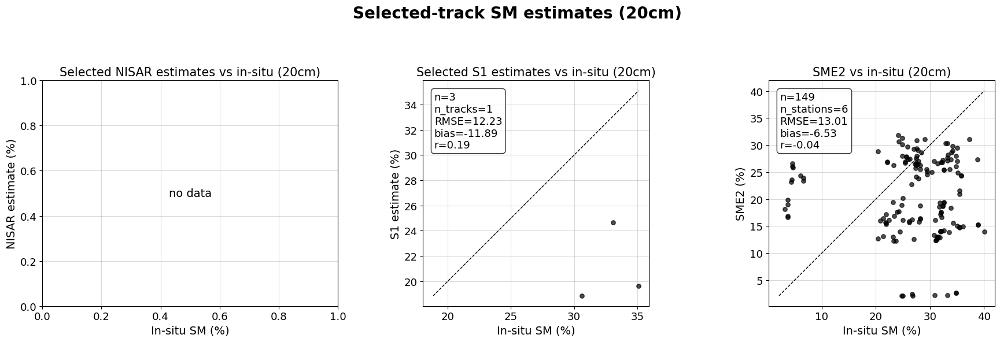

In [21]:
require_globals("plot_good_track_scatter_figure", "good_tracks_20cm")

plot_good_track_scatter_figure("20cm", DEPTH_SECONDARY, good_tracks_20cm, "Selected-track SM estimates (20cm)")


## Summary

`stations_to_plot` (Section 5) requires a 5cm SM estimate and 5cm in-situ
data. Section 9 screens each (station, satellite, track) at both depths and
applies user-editable `SELECTION_THRESHOLDS` to pick each depth's selected
tracks, which drive Section 10's highlighting on the per-station pages (up
to 4/station). Section 11 pools every selected 5cm track into 3 scatter
plots; Section 12 repeats it for 20cm.